# Inferring cortical pathways with HNN: NPE and NLE

EEG and MEG resolve neural activity in milliseconds, but a measured waveform alone does not reveal the underlying cellular and circuit mechanisms. The **Human Neocortical Neurosolver (HNN)** bridges these scales with a biophysical cortical-column model. Because its forward map is not easily amenable to standard statistical inference, it is a natural target for simulation-based inference (SBI).

This notebook infers eight HNN parameters in two ways:

1. **Neural posterior estimation (NPE)** learns the posterior directly.
2. **Neural likelihood estimation (NLE)** learns a likelihood and combines it with the same priors in PyMC.

We compare both posteriors and their HNN-based predictive fits on held-out simulations, then repeat the comparison on a recorded tactile-MEG waveform.

The formulation follows HNN's canonical three-drive event-related-potential (ERP) model. The [HNN batch-simulation tutorial](https://jonescompneurolab.github.io/textbook/content/08_using_hnn_api/batch_simulation.html), [ERP tutorial](https://jonescompneurolab.github.io/hnn-core/stable/auto_examples/workflows/plot_simulate_evoked.html), and [evoked-drive guide](https://jonescompneurolab.github.io/textbook/content/05_erps/erp_adjust_evoked_drives.html) provide the scientific background.

## 1. Modeling cortical dipoles

HNN represents a cortical column containing excitatory pyramidal cells and inhibitory basket cells in layers 2/3 and 5 of the neocortex. Synaptic currents flowing along aligned pyramidal dendrites form a net current dipole in nAm, directly comparable in principle with source-localized MEG or EEG.

<p align="center">
  <a href="https://jonescompneurolab.github.io/textbook/content/03_model_assumptions/synaptic_connectivity.html"><img src="https://raw.githubusercontent.com/jonescompneurolab/jones-website/ee71b1e43ea42fd97386ef4ed5c10ac30a6e274e/images/textbook/content/03_assumptions/images/synaptic-connectivity.png" width="48%" alt="HNN synaptic connectivity and current dipole"></a>
  <a href="https://jonescompneurolab.github.io/textbook/content/03_model_assumptions/synaptic_connectivity.html"><img src="https://raw.githubusercontent.com/jonescompneurolab/jones-website/ee71b1e43ea42fd97386ef4ed5c10ac30a6e274e/images/textbook/content/03_assumptions/images/3d-column-model.png" width="48%" alt="HNN cortical column and aggregate dipole"></a>
</p>

The canonical tactile ERP is generated by an ordered sequence of external drives:

| Drive | Biological interpretation | Synaptic location | Main waveform role |
|---|---|---|---|
| Early proximal | Fast feedforward / lemniscal thalamic input | Basal and oblique dendrites, near the soma | Initiates the early positive response |
| Distal | Feedback from higher cortex or non-lemniscal thalamus | Apical dendrites | Shapes the middle negative response |
| Late proximal | Re-entrant feedforward input | Proximal dendrites | Produces the later positive response |

Each drive retains HNN's published receptor- and cell-type-specific weight profile. We infer its arrival time and a pathway-wide strength multiplier. The dipole scale $a$ captures source-amplitude calibration, while $\sigma$ is the standard deviation of independent measurement noise.

For circuit parameters $\theta$, random input-event times $\xi$, and measurement noise $\epsilon_j$,

$$
x(t_j)=a\,\operatorname{HNN}(t_j;\theta,\xi)+\epsilon_j,
\qquad
\epsilon_j\sim\mathcal N(0,\sigma^2).
$$

We simulate waveforms up to 190 ms, smooth the aggregate dipole for 20 ms, apply HNN's standard scale factor of 3000, multiply by $a$, center each trace by its 10–20 ms mean, and retain one sample every 2 ms from 10 to 168 ms.

## 2. Parameters and priors

The timing variables are expressed as one arrival time and two positive gaps. This guarantees the biologically intended order:

$$
t_{\rm feedback}=t_{\rm early}+\Delta_{\rm feedback},
\qquad
t_{\rm late}=t_{\rm feedback}+\Delta_{\rm late}.
$$

All parameters are positive. The quoted 90% ranges describe prior mass, not truncation limits.

| Parameter | Plain-language meaning | Positive-support prior | Central 90% | Expected influence |
|---|---|---|---|---|
| Early feedforward time | When the first sensory volley reaches proximal dendrites | LogNormal(median 26.61 ms, log-SD 0.17) | 20.1–35.2 ms | Shifts the earliest response |
| Feedback delay | Time from early input to distal feedback | LogNormal(median 36.92 ms, log-SD 0.25) | 24.5–55.7 ms | Separates early and middle components |
| Late feedforward delay | Time from feedback to re-entrant proximal input | LogNormal(median 73.59 ms, log-SD 0.17) | 55.6–97.3 ms | Separates middle and late components |
| Early feedforward gain | Multiplier of the complete early-drive conductance profile | LogNormal(median 1, log-SD 0.70) | 0.316–3.16 | Changes early pathway recruitment |
| Feedback gain | Multiplier of all distal AMPA and NMDA conductances | LogNormal(median 1, log-SD 0.70) | 0.316–3.16 | Changes the middle and slower NMDA components |
| Late feedforward gain | Multiplier of the complete late-drive conductance profile | LogNormal(median 1, log-SD 0.70) | 0.316–3.16 | Changes the late response |
| Dipole amplitude scale | Relative source-amplitude calibration after HNN's standard scaling | Gamma(shape 2, rate 0.5) | 0.71–9.49 | Matches effective source extent without distorting circuit dynamics |
| Measurement noise SD $\sigma$ | Pointwise observation noise in nAm | 0.5 + LogNormal(median 1.5, log-SD 0.5) | 1.16–3.91 nAm | Controls fine-scale waveform variability |

The bundled waveforms already contain independent 0.5 nAm Gaussian noise. For each sampled $\sigma>0.5$, we add noise with SD $\sqrt{\sigma^2-0.5^2}$; variances add, so the resulting measurement noise has total SD $\sigma$. Regenerating the simulations uses $\sigma$ directly.


## 3. Simulation data

The bundled archive contains 4,096 training, 512 validation, and 256 test simulations as raw 80-point waveforms. We compute 20 PC scores and an empirical noise-SD estimate in memory.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

import bayesflow as bf
from bayesflow.wrappers.pymc import NeuralDistribution

import helpers as hnn
from inference import sample_nle_posterior, subset_draws
from plotting import (
    METHOD_COLORS, OBSERVED_COLOR, PCA_COLOR, PRIOR_COLOR,
    plot_posterior_comparison, plot_predictive_comparison,
)

print(f"BayesFlow {bf.__version__}")

INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': UNIMPLEMENTED: LoadPjrtPlugin is not implemented on windows yet.
INFO:jax._src.xla_bridge:Unable to initialize backend 'proxy': The 'proxy' backend requires the address of an IFRT Proxy server. Set it via the JAX_BACKEND_TARGET environment variable or the jax_backend_target config option, e.g. JAX_BACKEND_TARGET=grpc://localhost:29000.
INFO:bayesflow:Using backend 'jax'


BayesFlow 2.1.0


In [2]:
NPE_EPOCHS = 100
NLE_EPOCHS = 100
MCMC_DRAWS = 1000
MCMC_TUNE = 1000
MCMC_CHAINS = 4

N_JOBS = 4
N_PCA_COMPONENTS = 20
NPE_DROPOUT = 0.3
NLE_DROPOUT = 0.5
N_POSTERIOR_PREDICTIVE = 64

TIME_GRID = hnn.TIME_GRID
PARAMETER_NAMES = hnn.PARAMETER_NAMES
PARAMETER_LABELS = hnn.PARAMETER_LABELS
PRIOR_SPECS = hnn.PRIOR_SPECS

# Local randomness for selecting posterior draws; no global Keras seed.
rng = np.random.default_rng(2026)
sns.set_theme(style="white", context="notebook")

In [3]:
train, validation, test, cache_metadata = hnn.load_dataset()
print({name: split["dipole"].shape for name, split in (("train", train), ("validation", validation), ("test", test))})

{'train': (4096, 80), 'validation': (512, 80), 'test': (256, 80)}


### Prior-predictive waveforms

The same simulated waveforms are colored by each inferred parameter. The last panel shows how $\sigma$ controls pointwise variability.


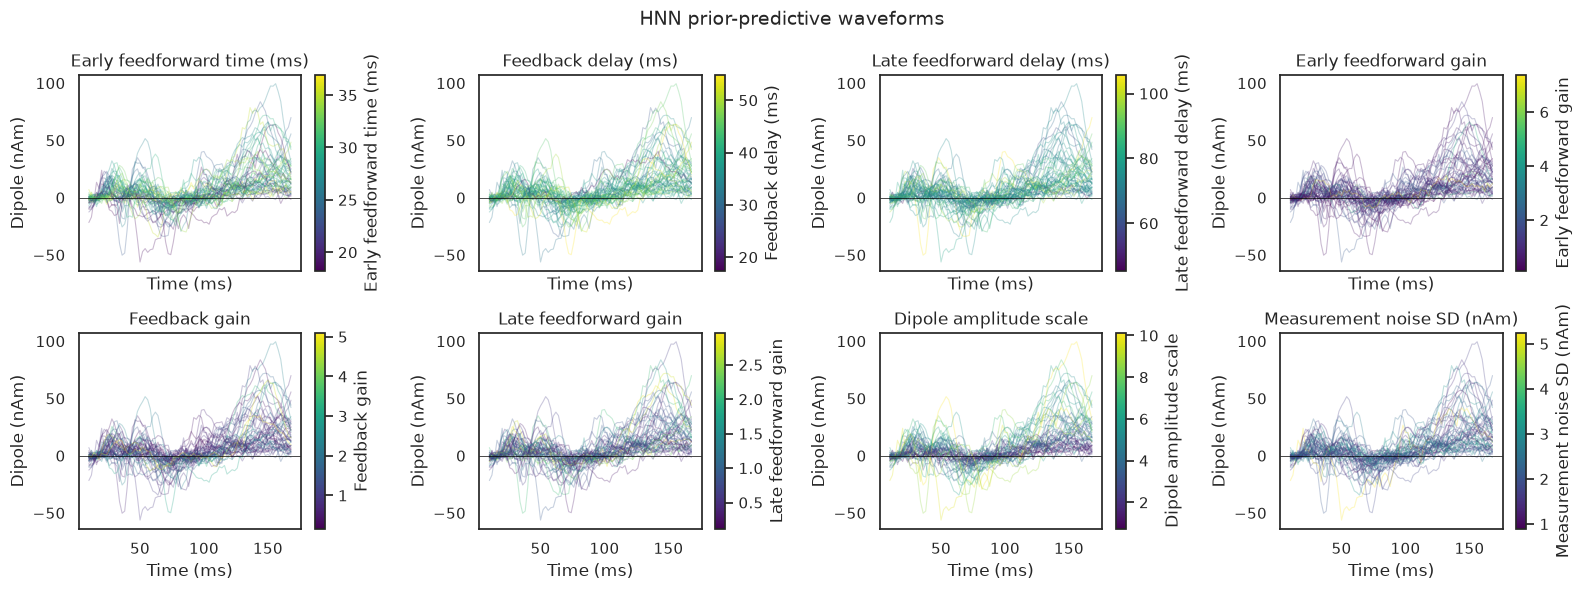

In [4]:
n_show = 50
show_indices = np.linspace(0, len(train["dipole"]) - 1, n_show, dtype=int)
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)

for axis, name, label in zip(axes.flat, PARAMETER_NAMES, PARAMETER_LABELS):
    values = train[name][show_indices, 0]
    normalization = plt.Normalize(values.min(), values.max())
    colors = plt.cm.viridis(normalization(values))

    for waveform, color in zip(train["dipole"][show_indices], colors):
        axis.plot(TIME_GRID, waveform, color=color, alpha=0.28, linewidth=0.8)

    colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=normalization, cmap="viridis"), ax=axis)
    colorbar.set_label(label)
    axis.axhline(0.0, color="black", linewidth=0.5)
    axis.set(title=label, xlabel="Time (ms)", ylabel="Dipole (nAm)")

for axis in axes.flat[len(PARAMETER_NAMES) :]:
    axis.remove()

fig.suptitle("HNN prior-predictive waveforms", fontsize=14)
fig.tight_layout()

### Dimensionality reduction using PCA

Both methods receive the same 20 PC scores, with the PCA basis fit only on the training split. PCA suppresses fine-scale variation, so we append an empirical noise SD computed from the high-frequency residual of a short Savitzky–Golay smooth.

For an interpretable comparison, the held-out case is selected near the center of the eight-dimensional training prior in standardized log coordinates. It is therefore a curated example; the NPE recovery plot later evaluates the complete test set.

In [5]:
pca = PCA(n_components=N_PCA_COMPONENTS, svd_solver="full")
train["dipole_pca"] = pca.fit_transform(train["dipole"])
train["empirical_noise_sd"] = hnn.empirical_noise_sd(train["dipole"])
train["dipole_summary"] = np.column_stack((train["dipole_pca"], train["empirical_noise_sd"]))

for split in (validation, test):
    split["dipole_pca"] = pca.transform(split["dipole"])
    split["empirical_noise_sd"] = hnn.empirical_noise_sd(split["dipole"])
    split["dipole_summary"] = np.column_stack((split["dipole_pca"], split["empirical_noise_sd"]))

log_train_parameters = np.column_stack([np.log(train[name][:, 0]) for name in PARAMETER_NAMES])
log_test_parameters = np.column_stack([np.log(test[name][:, 0]) for name in PARAMETER_NAMES])
prior_center = np.median(log_train_parameters, axis=0)
prior_scale = np.std(log_train_parameters, axis=0)
case_index = np.argmin(np.sum(((log_test_parameters - prior_center) / prior_scale) ** 2, axis=1))

case = {name: values[case_index : case_index + 1] for name, values in test.items()}
case_truth = {name: case[name][0, 0] for name in PARAMETER_NAMES}
case_reconstruction = pca.inverse_transform(case["dipole_pca"])[0]

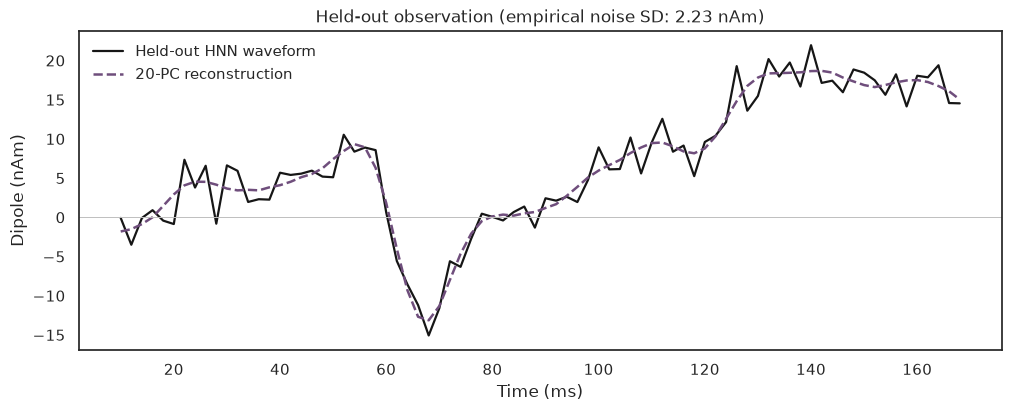

In [6]:
fig, axis = plt.subplots(figsize=(10, 4), layout="constrained")

axis.plot(TIME_GRID, case["dipole"][0], color=OBSERVED_COLOR, linewidth=1.6, label="Held-out HNN waveform")
axis.plot(
    TIME_GRID, case_reconstruction, color=PCA_COLOR, linestyle="--", linewidth=1.8,
    label=f"{N_PCA_COMPONENTS}-PC reconstruction"
)
axis.axhline(0.0, color="0.75", linewidth=0.7)
axis.set(
    title=f"Held-out observation (empirical noise SD: {case['empirical_noise_sd'][0, 0]:.2f} nAm)",
    xlabel="Time (ms)", ylabel="Dipole (nAm)",
)
axis.legend(frameon=False)

## 4. Neural posterior estimation

NPE learns $q_\phi(\theta\mid z)$ from the 20 PC scores and empirical noise-SD estimate. We log-transform the first seven parameters and the positive excess $\sigma-0.5$ before training.

In [7]:
npe_adapter = (
    bf.Adapter()
    .shift("measurement_noise_sd", by=-hnn.LEGACY_NOISE_SD)
    .log(PARAMETER_NAMES)
    .concatenate(PARAMETER_NAMES, into="inference_variables")
    .rename("dipole_summary", "inference_conditions")
)

npe_network = bf.networks.CouplingFlow(
    depth=2, 
    transform="spline", 
    subnet_kwargs={
        "widths": (64, 64), 
        "dropout": NPE_DROPOUT
    }
)

npe_workflow = bf.BasicWorkflow(
    adapter=npe_adapter, 
    inference_network=npe_network, 
    standardize="all", 
    initial_learning_rate=1e-3
)

npe_history = npe_workflow.fit_offline(train, validation_data=validation, epochs=NPE_EPOCHS, batch_size=512, verbose=0)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.


INFO:bayesflow:Building on a test batch.


INFO:bayesflow:Training completed in 12.77 seconds.


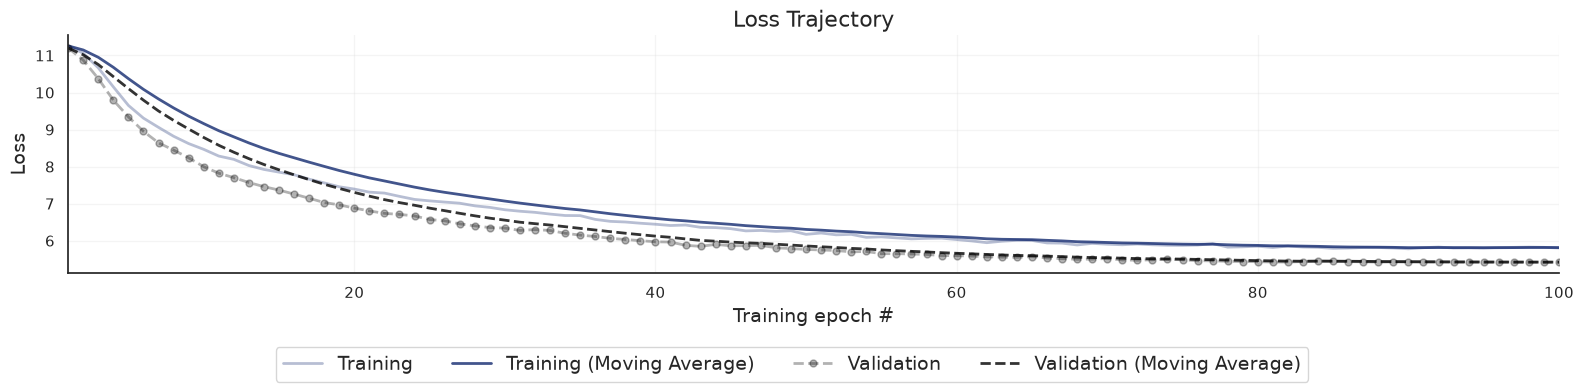

In [8]:
fig = bf.diagnostics.loss(npe_history)

Recovery on the full held-out test set checks whether posterior centers track the known generating values. The intervals also expose mechanisms that remain weakly identified under this fast budget.


In [9]:
npe_test_posterior = npe_workflow.sample(conditions={"dipole_summary": test["dipole_summary"]}, num_samples=500)

INFO:bayesflow:Sampling completed in 2.38 seconds.


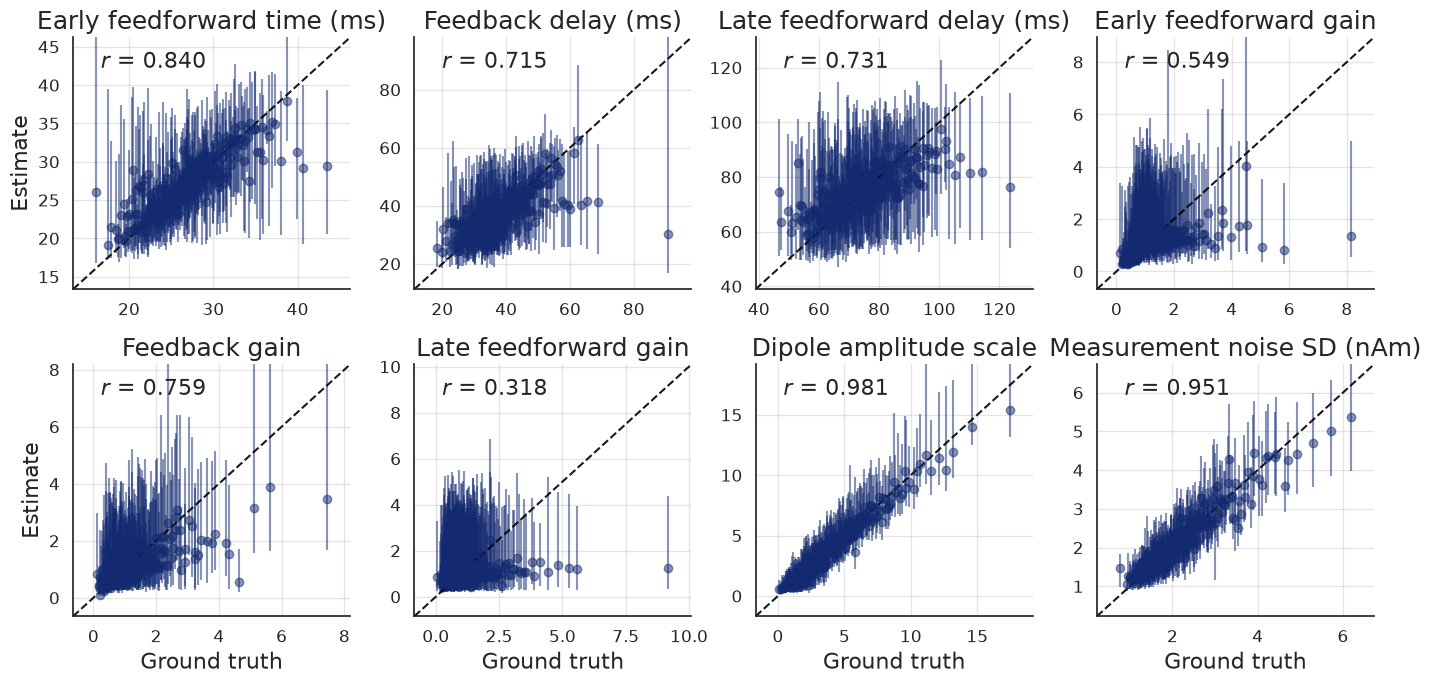

In [10]:
fig = bf.diagnostics.recovery(
    npe_test_posterior,
    test,
    variable_keys=PARAMETER_NAMES,
    variable_names=PARAMETER_LABELS,
    figsize=(14, 7),
    num_col=4,
    num_row=2,
)

> NLE amortizes likelihood evaluation, but obtaining each posterior still requires a separate MCMC run. We omit the test-set-wide NLE recovery plot to keep this workshop manageable. NPE produces posterior samples directly for every test observation. As an exercise, add simulation-based calibration (SBC) and assess coverage; a recovery plot alone does not establish calibration.

In [11]:
npe_case_posterior = npe_workflow.sample(conditions={"dipole_summary": case["dipole_summary"]}, num_samples=2000)

INFO:bayesflow:Sampling completed in 1.36 seconds.


## 5. Neural likelihood estimation

NLE estimates $q_\psi(z\mid\theta)$ from the same 21-dimensional summary and transformed parameters. Posterior inference then uses PyMC.

In [12]:
nle_adapter = (
    bf.Adapter()
    .shift("measurement_noise_sd", by=-hnn.LEGACY_NOISE_SD)
    .log(PARAMETER_NAMES)
    .concatenate(PARAMETER_NAMES, into="inference_conditions")
    .rename("dipole_summary", "inference_variables")
)

nle_network = bf.networks.CouplingFlow(
    depth=2, 
    transform="spline", 
    subnet_kwargs={
        "widths": (128, 128), 
        "dropout": NLE_DROPOUT
    }
)

nle_workflow = bf.BasicWorkflow(
    adapter=nle_adapter, 
    inference_network=nle_network, 
    standardize="all", 
    initial_learning_rate=5e-4
)

nle_history = nle_workflow.fit_offline(train, validation_data=validation, epochs=NLE_EPOCHS, batch_size=128, verbose=0)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.


INFO:bayesflow:Building on a test batch.


INFO:bayesflow:Training completed in 37.64 seconds.


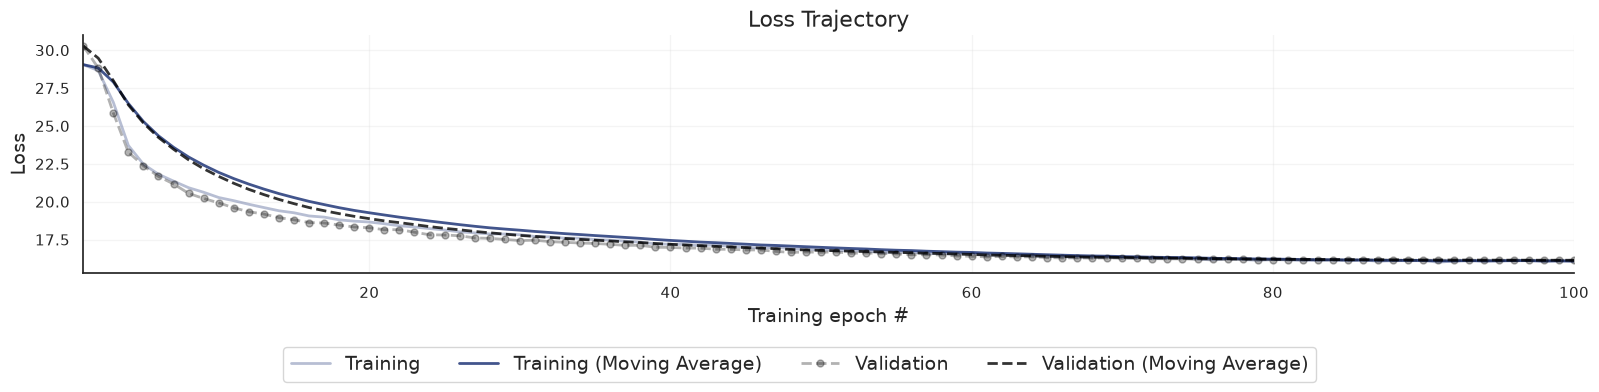

In [13]:
fig = bf.diagnostics.loss(nle_history)

PyMC uses the same priors, including the shifted LogNormal prior for $\sigma$. `NeuralDistribution` connects the trained likelihood to NUTS.

In [14]:
log_names = [f"log_{name}" for name in PARAMETER_NAMES[:-1]] + ["log_measurement_noise_excess"]
neural_likelihood = NeuralDistribution(
    estimator=nle_workflow.estimator,
    param_names=log_names,
    exchangeable=False,
)

nle_trace = sample_nle_posterior(
    neural_likelihood, case["dipole_summary"],
    draws=MCMC_DRAWS, tune=MCMC_TUNE, chains=MCMC_CHAINS,
)

INFO:pymc.sampling.mcmc:Initializing NUTS using jitter+adapt_diag...


/home/radevs/Desktop/Projects/princeton-workshop-2026/.venv/lib/python3.12/site-packages/pytensor/link/c/cmodule.py:2986: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(


INFO:pymc.sampling.mcmc:Sequential sampling (4 chains in 1 job)


INFO:pymc.sampling.mcmc:NUTS: [early_feedforward_time, feedback_delay, late_feedforward_delay, early_feedforward_gain, feedback_gain, late_feedforward_gain, observation_gain, measurement_noise_excess]


Output()

INFO:pymc.sampling.mcmc:Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 79 seconds.


In [15]:
az.summary(nle_trace, var_names=PARAMETER_NAMES, hdi_prob=0.9, round_to=3)

,mean,sd,hdi_5%,hdi_95%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
early_feedforward_time,28.188,3.266,23.045,33.456,0.064,0.051,2622.816,2603.711,1.001
feedback_delay,36.441,5.791,27.733,46.245,0.123,0.102,2194.749,2217.487,1.001
late_feedforward_delay,72.697,7.366,60.788,84.050,0.167,0.136,1960.063,2319.870,1.002
early_feedforward_gain,1.019,0.528,0.348,1.680,0.011,0.020,3143.982,2052.559,1.000
feedback_gain,0.797,0.427,0.217,1.346,0.008,0.014,2870.657,2730.244,1.002
late_feedforward_gain,1.415,0.907,0.288,2.596,0.019,0.029,2296.690,2396.004,1.001
observation_gain,2.720,0.431,2.023,3.414,0.009,0.007,2384.147,2418.053,1.000
measurement_noise_sd,2.237,0.277,1.792,2.652,0.006,0.008,2486.280,2076.851,1.001


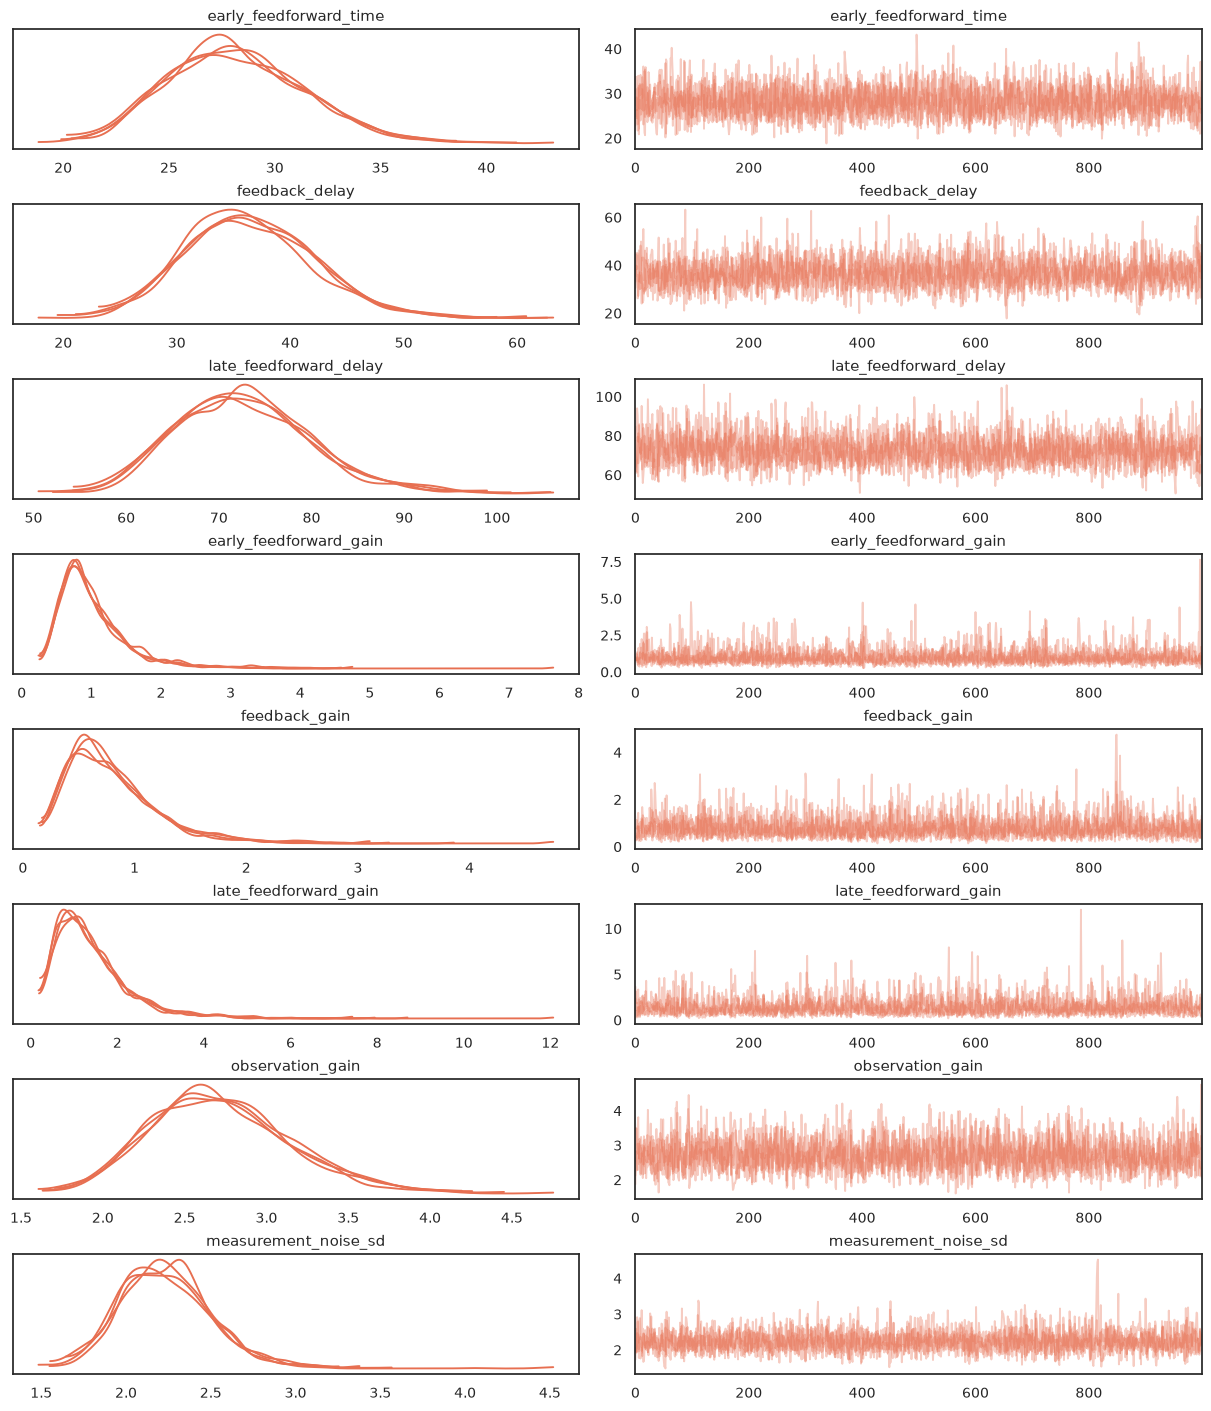

In [16]:
axes = az.plot_trace(
    nle_trace,
    var_names=PARAMETER_NAMES,
    figsize=(12, 14),
    chain_prop={"color": [METHOD_COLORS["NLE"]]},
    backend_kwargs={"layout": "constrained"},
)

## 6. Posterior comparison on a held-out HNN waveform

Both methods saw the same training simulations, 21-dimensional summary, held-out observation, and priors. We can now compare the resulting posteriors.

In [17]:
npe_draws = {name: npe_case_posterior[name].ravel() for name in PARAMETER_NAMES}
nle_draws = {name: nle_trace.posterior[name].values.ravel() for name in PARAMETER_NAMES}

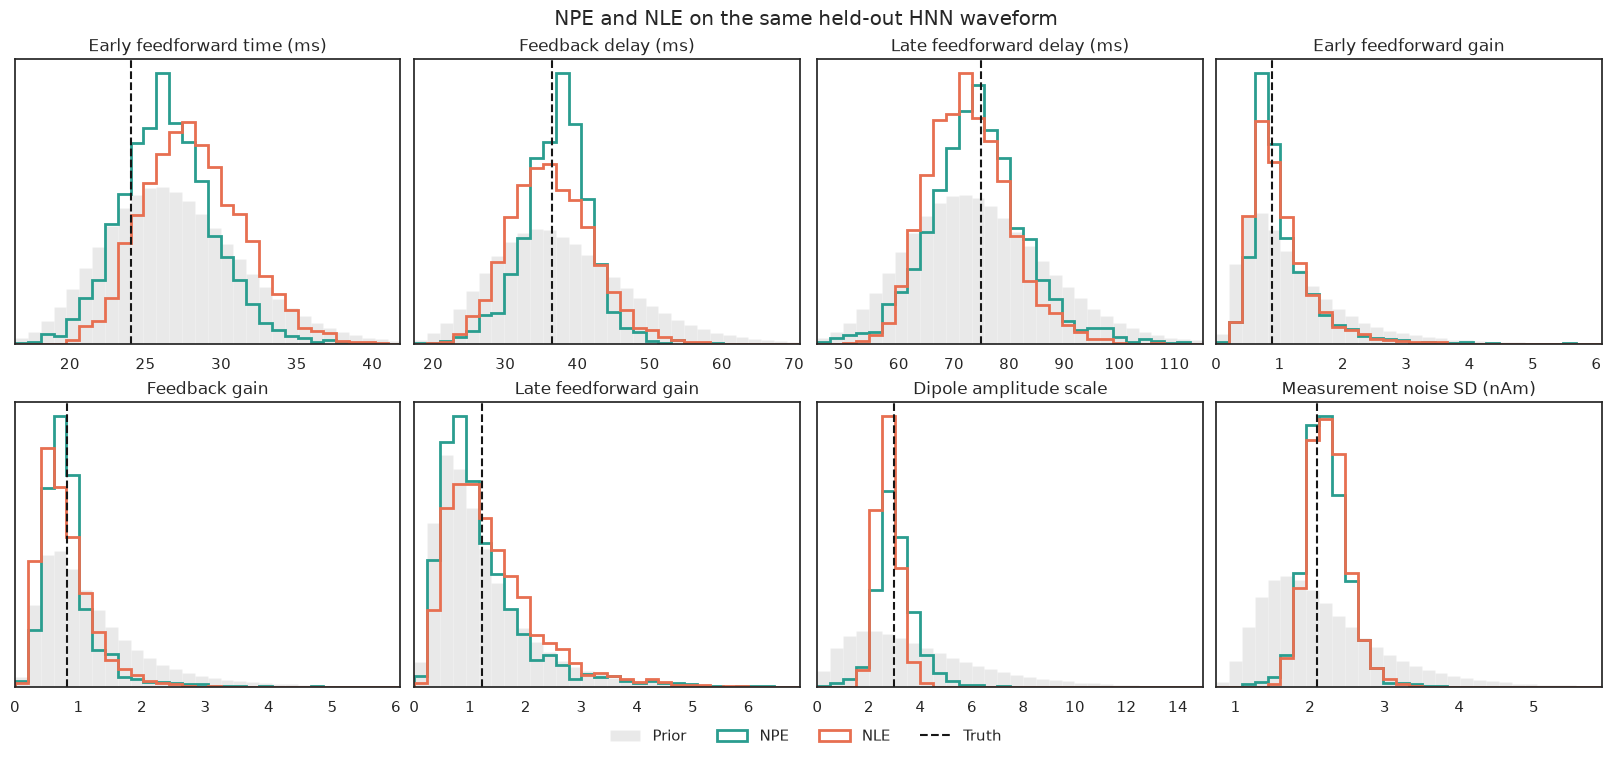

In [18]:
fig = plot_posterior_comparison(
    npe_draws,
    nle_draws,
    train,
    truth=case_truth,
    title="NPE and NLE on the same held-out HNN waveform",
)

Compare the centers and widths rather than assuming the methods agree. Differences may reflect neural approximation error, insufficient training, or MCMC convergence problems. Check the validation losses and ArviZ diagnostics above before interpreting the posterior.

In [19]:
comparison_rows = []
for name, label in zip(PARAMETER_NAMES, PARAMETER_LABELS):
    row = {"parameter": label, "truth": case_truth[name]}

    for method, draws in (("NPE", npe_draws[name]), ("NLE", nle_draws[name])):
        lower, median, upper = np.quantile(draws, [0.05, 0.5, 0.95])
        row[f"{method} median"] = median
        row[f"{method} 90% interval"] = f"[{lower:.3f}, {upper:.3f}]"

    comparison_rows.append(row)

pd.DataFrame(comparison_rows)

,parameter,truth,NPE median,NPE 90% interval,NLE median,NLE 90% interval
0,Early feedforward time (ms),24.058228,26.312129,"[21.653, 31.610]",27.943743,"[23.253, 33.856]"
1,Feedback delay (ms),36.503475,37.375051,"[29.061, 44.129]",36.030632,"[27.619, 46.160]"
2,Late feedforward delay (ms),74.945572,73.838013,"[60.485, 88.866]",72.236164,"[61.727, 85.557]"
3,Early feedforward gain,0.885410,0.867847,"[0.491, 2.053]",0.884151,"[0.466, 2.008]"
4,Feedback gain,0.824710,0.759919,"[0.368, 1.618]",0.709990,"[0.304, 1.615]"
5,Late feedforward gain,1.207510,0.968226,"[0.359, 2.982]",1.196961,"[0.445, 3.100]"
6,Dipole amplitude scale,2.979601,2.938041,"[1.958, 4.425]",2.683898,"[2.076, 3.485]"
7,Measurement noise SD (nAm),2.092586,2.191162,"[1.778, 2.715]",2.217219,"[1.828, 2.714]"


## 7. HNN posterior predictive checks

Posterior predictive checking feeds posterior draws back through the original simulator. It asks whether the inferred mechanism can generate waveforms resembling the observed one, including stochastic variation.

The next cell runs 128 new HNN simulations: 64 posterior draws from each method.

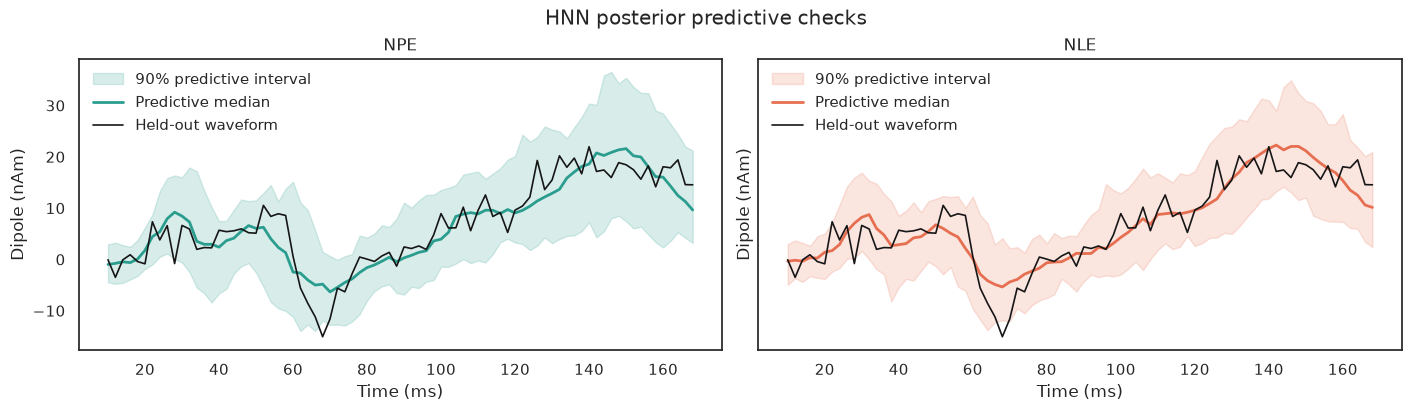

In [20]:
held_out_parameters = {
    "NPE": subset_draws(npe_draws, N_POSTERIOR_PREDICTIVE, rng=rng),
    "NLE": subset_draws(nle_draws, N_POSTERIOR_PREDICTIVE, rng=rng),
}
held_out_predictives = {
    method: hnn.simulate_parameter_batch(parameters, n_jobs=N_JOBS)
    for method, parameters in held_out_parameters.items()
}
fig = plot_predictive_comparison(
    held_out_predictives, case["dipole"][0],
    observed_label="Held-out waveform", title="HNN posterior predictive checks",
)

## 8. Analyzing real tactile MEG data

HNN publishes a [source-localized S1 dipole](https://github.com/jonescompneurolab/hnn-data/blob/main/MEG_detection_data/yes_trial_S1_ERP_all_avg.txt) from a tactile-detection experiment. We will now perform inference on that data, compare posteriors, and perform posterior predictive checks.

Real data that are highly unlikely under the prior predictive may result in biased posterior approximations. Amortized Bayesian inference is trained on the model-implied distribution $p(x)=\mathbb{E}_{p(\theta)}[p(x\mid\theta)]$, so observations $x_{\mathrm{obs}}$ outside its typical set force the network to extrapolate. The potential **extrapolation bias** can make $q(\theta\mid x_{\mathrm{obs}})$ unreliable even when inference is accurate for typical simulations. Comparing observed summaries $\phi(x_{\mathrm{obs}})$ with the prior-predictive distribution of $\phi(x)$ is therefore a useful diagnostic.

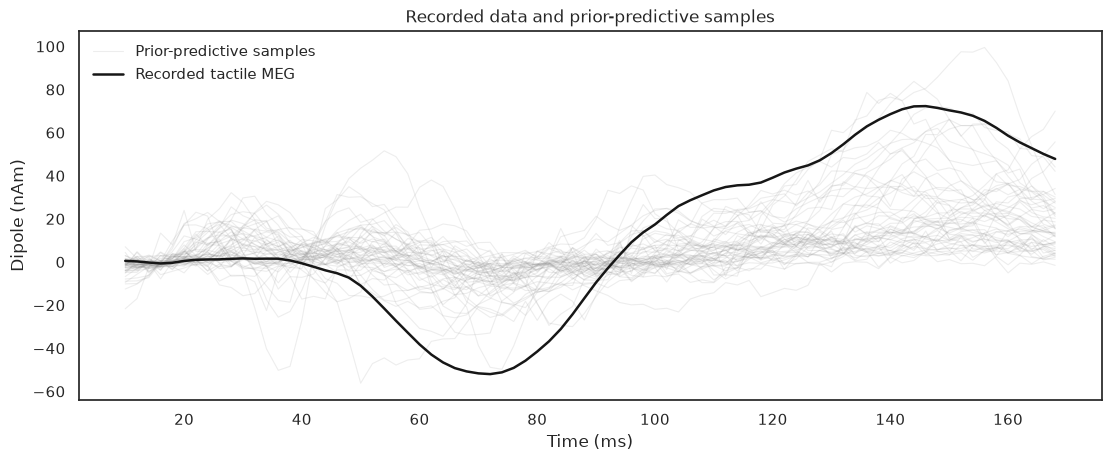

In [21]:
experimental_waveform = hnn.load_experimental_waveform()
experimental_pca = pca.transform(experimental_waveform[None, :])
experimental_noise_sd = hnn.empirical_noise_sd(experimental_waveform)
experimental_summary = np.column_stack((experimental_pca, experimental_noise_sd))

fig, axis = plt.subplots(figsize=(11, 4.5), layout="constrained")
axis.plot(
    TIME_GRID, train["dipole"][show_indices[0]], color=PRIOR_COLOR, alpha=0.15, linewidth=0.8,
    label="Prior-predictive samples",
)
for waveform in train["dipole"][show_indices[1:]]:
    axis.plot(TIME_GRID, waveform, color=PRIOR_COLOR, alpha=0.15, linewidth=0.8)

axis.plot(TIME_GRID, experimental_waveform, color=OBSERVED_COLOR, linewidth=1.8, label="Recorded tactile MEG")
axis.set(title="Recorded data and prior-predictive samples", xlabel="Time (ms)", ylabel="Dipole (nAm)")
axis.legend(frameon=False)

NPE is amortized and just needs a batch of forward passes:

In [22]:
experimental_npe_raw = npe_workflow.sample(conditions={"dipole_summary": experimental_summary}, num_samples=2000)

INFO:bayesflow:Sampling completed in 0.02 seconds.


NLE combines the amortized likelihood with the prior and runs MCMC again for this new observation:

In [23]:
experimental_nle_trace = sample_nle_posterior(
    neural_likelihood, experimental_summary,
    draws=MCMC_DRAWS, tune=MCMC_TUNE, chains=MCMC_CHAINS,
    random_seed=2027,
)

INFO:pymc.sampling.mcmc:Initializing NUTS using jitter+adapt_diag...


INFO:pymc.sampling.mcmc:Sequential sampling (4 chains in 1 job)


INFO:pymc.sampling.mcmc:NUTS: [early_feedforward_time, feedback_delay, late_feedforward_delay, early_feedforward_gain, feedback_gain, late_feedforward_gain, observation_gain, measurement_noise_excess]


Output()

INFO:pymc.sampling.mcmc:Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 75 seconds.


Which also means we have access to all the canonical MCMC diagnostics:

In [24]:
az.summary(experimental_nle_trace, var_names=PARAMETER_NAMES, hdi_prob=0.9, round_to=3)

,mean,sd,hdi_5%,hdi_95%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
early_feedforward_time,22.461,2.944,18.033,26.694,0.063,0.074,2399.924,2028.738,1.001
feedback_delay,38.474,5.831,28.825,47.969,0.129,0.092,2018.836,2443.496,1.003
late_feedforward_delay,77.832,8.214,64.272,91.160,0.193,0.130,1810.235,2651.113,1.005
early_feedforward_gain,0.618,0.344,0.183,1.060,0.007,0.012,2919.751,2064.892,1.000
feedback_gain,1.491,0.814,0.359,2.548,0.016,0.025,2689.329,2526.754,1.000
late_feedforward_gain,1.451,0.968,0.323,2.675,0.019,0.037,2843.191,2236.666,1.001
observation_gain,12.251,1.683,9.406,14.871,0.033,0.025,2676.573,2675.038,1.001
measurement_noise_sd,1.877,0.582,1.113,2.745,0.012,0.017,2788.667,1805.756,1.000


In [25]:
experimental_npe = {name: experimental_npe_raw[name].ravel() for name in PARAMETER_NAMES}
experimental_nle = {
    name: experimental_nle_trace.posterior[name].values.ravel()
    for name in PARAMETER_NAMES
}

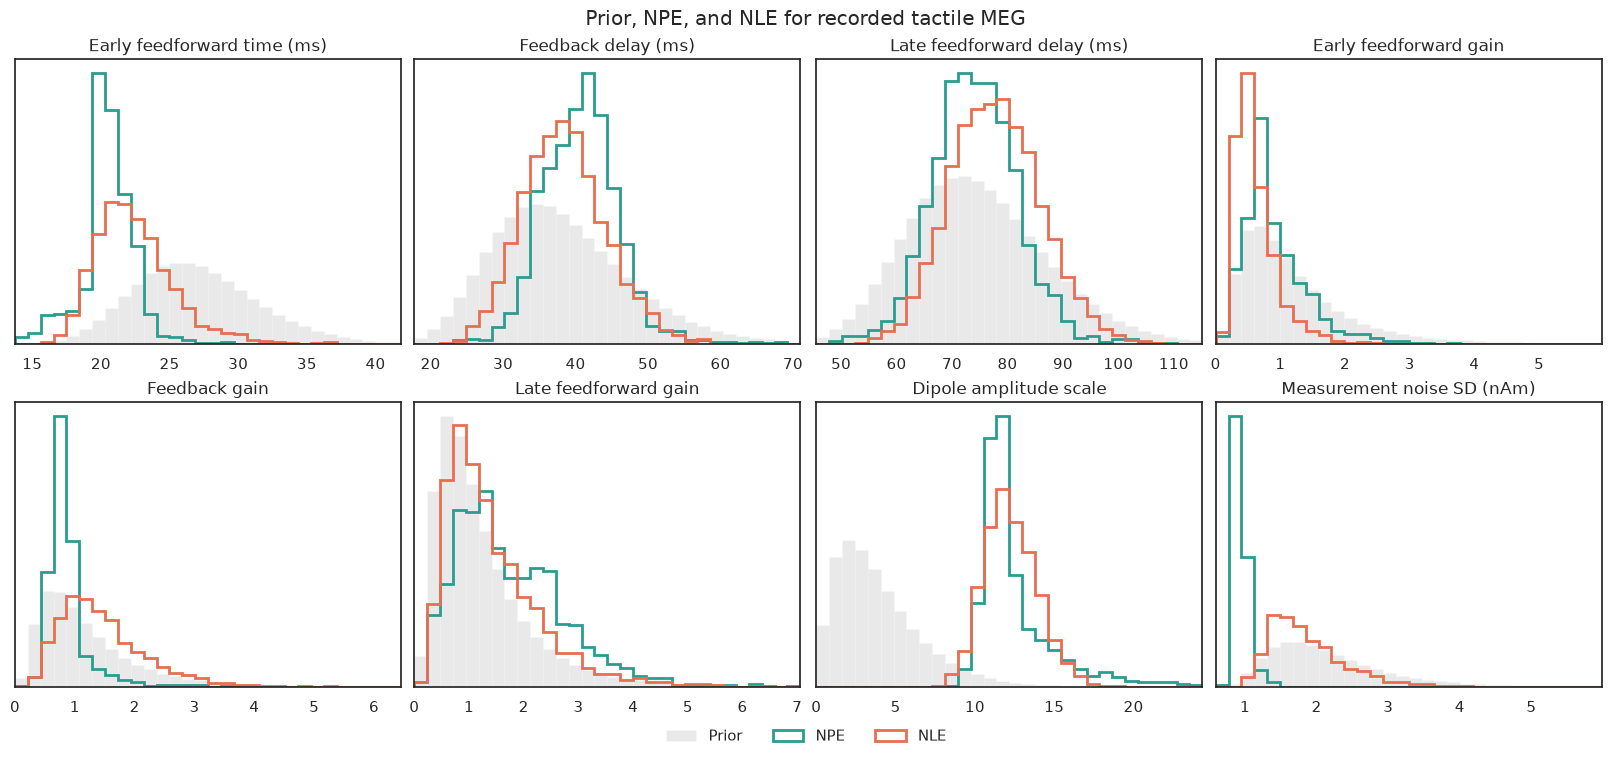

In [26]:
fig = plot_posterior_comparison(
    experimental_npe,
    experimental_nle,
    train,
    title="Prior, NPE, and NLE for recorded tactile MEG",
)

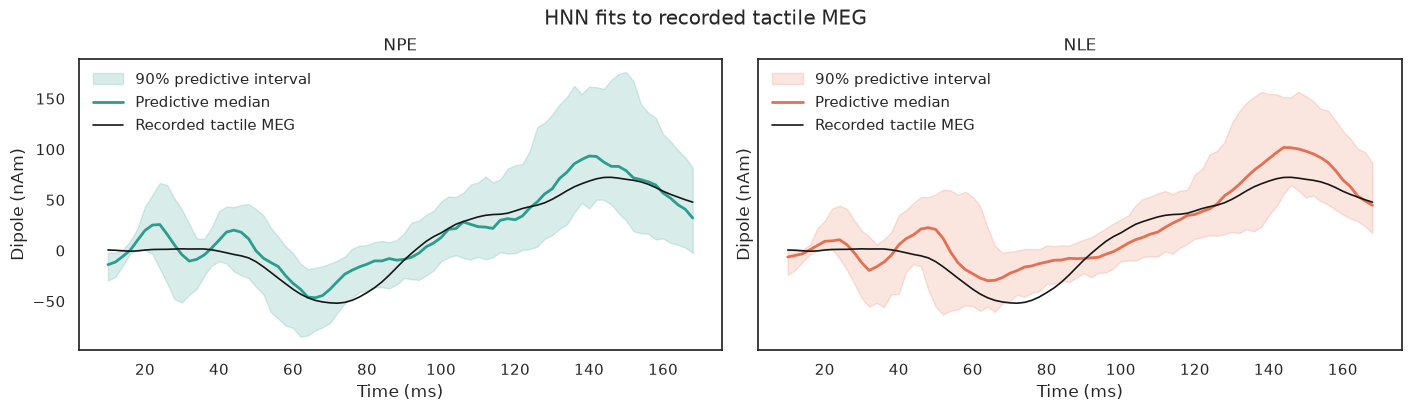

In [27]:
experimental_parameters = {
    "NPE": subset_draws(experimental_npe, N_POSTERIOR_PREDICTIVE, rng=rng),
    "NLE": subset_draws(experimental_nle, N_POSTERIOR_PREDICTIVE, rng=rng),
}

experimental_predictives = {
    method: hnn.simulate_parameter_batch(parameters, n_jobs=N_JOBS)
    for method, parameters in experimental_parameters.items()
}

fig = plot_predictive_comparison(
    experimental_predictives, experimental_waveform,
    observed_label="Recorded tactile MEG", title="HNN fits to recorded tactile MEG",
)

## 9. Further steps

Explore `EnsembleWorkflow` with different inference networks to assess how the network architecture affects the posterior. You can also replace PCA with a trainable summary network so that waveform features are learned jointly with inference.


Try increasing the training budgets, run SBC on held-out data, compare multiple simulated observations, and inspect the PCA reconstruction of the recorded waveform. Posterior agreement is not a guarantee of scientific validity: both methods share the simulator, priors, and PCA compression, and the real recording can differ from those assumptions.